<a href="https://colab.research.google.com/github/kavyagudiwada/Machine-Learning_LAB_AP24110010791/blob/main/Preprocessing_HandsOn_LAB_AP24110010791.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing Lab: Getting Data ML-Ready

## Student Practice Notebook

**Name:** GUDIWADA KARUNA NAGA VENKATA KAVYA SREE

**Register Number:** AP24110010791  

**Date:** 22-08-2026  

## Learning Objectives

After completing this lab, you will be able to:

- Handle missing data with justified strategies (not just delete-everything)
- Encode categorical variables into numeric form (label encoding, one-hot encoding)
- Scale/normalize numeric features (min-max scaling, standardization)
- Detect and handle outliers
- Split data into train/test sets correctly
- Apply preprocessing to image data (pixel normalization) and text data (numeric encoding)

### Why this week matters
Every ML model needs **numbers, on a similar scale, with no gaps**. Raw pandas data (mixed types, missing values, unscaled numbers) can't go directly into a model. This lab is the bridge between "clean data" (last week) and "model-ready data" (next steps in your course).

### How to use this notebook
Same as before: **demo → practice → predict-then-run → reflect.**


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.precision', 3)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
tips = pd.read_csv(url)
tips['tip_pct'] = tips['tip'] / tips['total_bill']
tips.head()


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,0.059
1,10.34,1.66,Male,No,Sun,Dinner,3,0.161
2,21.01,3.50,Male,No,Sun,Dinner,3,0.167
3,23.68,3.31,Male,No,Sun,Dinner,2,0.140
4,24.59,3.61,Female,No,Sun,Dinner,4,0.147


## Part 1: Missing Data — Choosing a Strategy

Last week you dropped or filled missing values without much thought about *which* to choose. This week: which strategy is right depends on the situation.

### Demonstration


In [4]:
tips_missing = tips.copy()
np.random.seed(42)
missing_idx = np.random.choice(tips_missing.index, size=15, replace=False)
tips_missing.loc[missing_idx, 'total_bill'] = np.nan

print("Missing values:", tips_missing['total_bill'].isna().sum())
print("Percentage missing: {:.1f}%".format(100 * tips_missing['total_bill'].isna().sum() / len(tips_missing)))


Missing values: 15
Percentage missing: 6.1%


**Common strategies:**
- **Drop rows** — safe when missing % is small AND rows are random (not systematically missing)
- **Fill with mean/median** — good for numeric columns; median is safer when outliers exist
- **Fill with mode** — for categorical columns
- **Fill with group-wise mean** — smarter: fill using the mean *within a relevant group* instead of the global mean

### Demonstration: group-wise fill (smarter than global mean)


In [5]:
# Instead of filling with the overall mean, fill using each day's own mean
# This preserves day-to-day differences instead of flattening everything to one number

day_means = tips_missing.groupby('day')['total_bill'].transform('mean')
tips_filled = tips_missing.copy()
tips_missing_filled_bill = tips_missing['total_bill'].fillna(day_means)
tips_filled['total_bill'] = tips_missing_filled_bill

print("Remaining missing:", tips_filled['total_bill'].isna().sum())


Remaining missing: 0


### Student Practice

1. Create missing values in the `tip` column (5 random rows) the same way as the demo.
2. Fill them using the **median** `tip` grouped by `time` (Lunch/Dinner) instead of by day.
3. In 1-2 sentences, justify why you chose group-by-`time` over a global fill for this column.


In [6]:
# Write your answer here
# 1. Create 5 missing values in the tip column
tips_practice = tips.copy()

np.random.seed(42)
missing_idx = np.random.choice(tips_practice.index, size=5, replace=False)
tips_practice.loc[missing_idx, 'tip'] = np.nan

print("Missing values:", tips_practice['tip'].isna().sum())


# 2. Calculate median tip for each time (Lunch/Dinner)
time_medians = tips_practice.groupby('time')['tip'].transform('median')

# 3. Fill missing tip values using the median of their time group
tips_practice['tip'] = tips_practice['tip'].fillna(time_medians)

print("Remaining missing:", tips_practice['tip'].isna().sum())

Missing values: 5
Remaining missing: 0


**Reflection:** Why might filling missing values with a *group-wise* mean/median be better than a single global mean? Give a concrete scenario where this would matter.

*Your answer:*


I chose group-by-time because tips may differ between Lunch and Dinner. Using the median within each time group preserves these differences better than using one global median.

## Part 2: Encoding Categorical Variables

ML models need numbers — they can't use `"Male"`, `"Sun"`, `"Yes"` directly. We need to **encode** categories into numeric form.

### 2a. Label Encoding (for ordinal/binary categories)

### Demonstration


In [7]:
tips_enc = tips.copy()

# Binary categories: map directly to 0/1
tips_enc['sex_encoded'] = tips_enc['sex'].map({'Male': 0, 'Female': 1})
tips_enc['smoker_encoded'] = tips_enc['smoker'].map({'No': 0, 'Yes': 1})

tips_enc[['sex','sex_encoded','smoker','smoker_encoded']].head()


,sex,sex_encoded,smoker,smoker_encoded
0,Female,1,No,0
1,Male,0,No,0
2,Male,0,No,0
3,Male,0,No,0
4,Female,1,No,0


### 2b. One-Hot Encoding (for categories with no natural order)

`day` has 4 categories with no inherent ranking (Thur isn't "less than" Fri). Label encoding (0,1,2,3) would wrongly imply an order. **One-hot encoding** creates a separate 0/1 column per category instead.

### Demonstration


In [8]:
day_dummies = pd.get_dummies(tips_enc['day'], prefix='day')
tips_enc = pd.concat([tips_enc, day_dummies], axis=1)
tips_enc[['day','day_Thur','day_Fri','day_Sat','day_Sun']].head()


,day,day_Thur,day_Fri,day_Sat,day_Sun
0,Sun,False,False,False,True
1,Sun,False,False,False,True
2,Sun,False,False,False,True
3,Sun,False,False,False,True
4,Sun,False,False,False,True


### Student Practice — predict then check

`time` has 2 categories (Lunch, Dinner). Predict: should you use label encoding or one-hot encoding for `time`, and why? Write your prediction, then implement whichever you chose.

*Your prediction:*


In [9]:
# Write your answer here
pd.get_dummies(tips['time'], dtype=int)

,Dinner,Lunch
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
...,...,...
239,1,0
240,1,0
241,1,0
242,1,0


**Reflection:** Why would label-encoding `day` as Thur=0, Fri=1, Sat=2, Sun=3 be misleading to a model, even though it's technically valid Python code?

*Your answer:*

Label encoding would be misleading because it gives the days an artificial numerical order: Thur < Fri < Sat < Sun. This may make the model think that Sunday is “greater” than Saturday and that the difference between each day is meaningful, even though day is a categorical variable with no natural numerical relationship.


## Part 3: Feature Scaling

`total_bill` ranges roughly 3-50, while `tip_pct` ranges roughly 0-1. Many ML algorithms (e.g. distance-based ones like KNN, or gradient-based ones) perform poorly when features are on very different scales — a large-range feature can dominate just because of its scale, not because it's more important.

### 3a. Min-Max Scaling (rescales to a fixed 0-1 range)

### Demonstration


In [10]:
def min_max_scale(series):
    return (series - series.min()) / (series.max() - series.min())

tips_enc['total_bill_scaled'] = min_max_scale(tips_enc['total_bill'])
tips_enc[['total_bill','total_bill_scaled']].describe()


,total_bill,total_bill_scaled
count,244.000,244.000
mean,19.786,0.350
std,8.902,0.186
min,3.070,0.000
25%,13.348,0.215
50%,17.795,0.308
75%,24.127,0.441
max,50.810,1.000


### 3b. Standardization (rescales to mean=0, std=1)

### Demonstration


In [11]:
def standardize(series):
    return (series - series.mean()) / series.std()

tips_enc['total_bill_standardized'] = standardize(tips_enc['total_bill'])
tips_enc[['total_bill','total_bill_standardized']].describe()


,total_bill,total_bill_standardized
count,244.000,2.440e+02
mean,19.786,-6.029e-17
std,8.902,1.000e+00
min,3.070,-1.878e+00
25%,13.348,-7.232e-01
50%,17.795,-2.236e-01
75%,24.127,4.877e-01
max,50.810,3.485e+00


### Student Practice — predict then check

Predict: after standardizing, what will the **mean** of `total_bill_standardized` be (approximately)? What about the standard deviation? Write your prediction, then verify with `.mean()` and `.std()`.

*Your prediction:*


After standardization:

Mean: approximately 0
Standard deviation: approximately 1

Now apply **min-max scaling** to the `size` column and store it as `size_scaled`.


In [14]:
# Write your answer here


print("Mean:", tips_enc['total_bill_standardized'].mean())
print("Standard deviation:", tips_enc['total_bill_standardized'].std())

Mean: -6.028875031263658e-17
Standard deviation: 1.0


In [15]:
tips_enc['size_scaled'] = (
    (tips_enc['size'] - tips_enc['size'].min()) /
    (tips_enc['size'].max() - tips_enc['size'].min())
)

In [16]:
tips_enc[['size', 'size_scaled']].head()

,size,size_scaled
0,2,0.2
1,3,0.4
2,3,0.4
3,2,0.2
4,4,0.6


**Reflection:** In your own words, what's the difference between min-max scaling and standardization? When might you prefer one over the other? (Hint: think about what happens to each with extreme outliers.)

*Your answer:*


Min-max scaling changes values to a range between 0 and 1, while standardization changes values so that the mean is 0 and the standard deviation is 1. Min-max scaling is more affected by extreme outliers because the minimum and maximum determine the range. Standardization is generally preferred when the data has outliers or when the ML algorithm works better with normally distributed standardized features.


## Part 4: Outlier Detection and Handling

Outliers are unusually extreme values that can distort model training. A common rule: values beyond **1.5 × IQR** (interquartile range) from Q1/Q3 are considered outliers.

### Demonstration


In [17]:
Q1 = tips['total_bill'].quantile(0.25)
Q3 = tips['total_bill'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = tips[(tips['total_bill'] < lower_bound) | (tips['total_bill'] > upper_bound)]
print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of outliers: {len(outliers)}")
outliers[['total_bill','day','size']]


Bounds: [-2.82, 40.30]
Number of outliers: 9


,total_bill,day,size
59,48.27,Sat,4
102,44.30,Sat,3
142,41.19,Thur,5
156,48.17,Sun,6
170,50.81,Sat,3
182,45.35,Sun,3
184,40.55,Sun,2
197,43.11,Thur,4
212,48.33,Sat,4


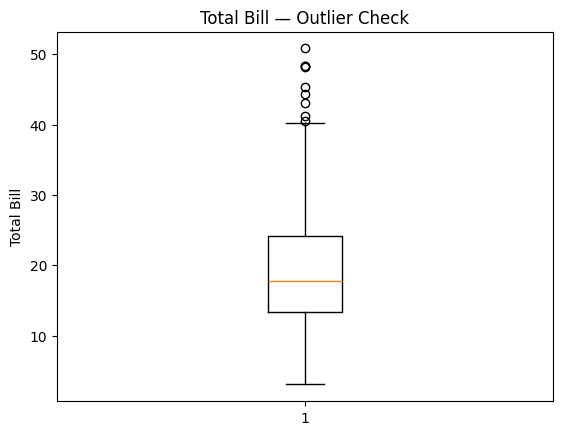

In [18]:
# Visualize outliers with a boxplot
plt.figure()
plt.boxplot(tips['total_bill'])
plt.title("Total Bill — Outlier Check")
plt.ylabel("Total Bill")
plt.show()


### Student Practice

1. Run the same IQR outlier check on the `tip` column.
2. Instead of dropping outliers, **cap** them: replace any value above `upper_bound` with `upper_bound` itself, and any value below `lower_bound` with `lower_bound` (this is called "capping" or "winsorizing" — it keeps the row but limits the extreme value).


In [19]:
# Write your answer here

Q1 = tips['tip'].quantile(0.25)
Q3 = tips['tip'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = tips[
    (tips['tip'] < lower_bound) |
    (tips['tip'] > upper_bound)
]

print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of outliers: {len(outliers)}")

outliers[['tip', 'day', 'size']]

Bounds: [-0.34, 5.91]
Number of outliers: 9


,tip,day,size
23,7.58,Sat,4
47,6.00,Sun,4
59,6.73,Sat,4
141,6.70,Thur,6
170,10.00,Sat,3
183,6.50,Sun,4
212,9.00,Sat,4
214,6.50,Sat,3
239,5.92,Sat,3


In [22]:
tips['tip_capped'] = tips['tip'].clip(
    lower=lower_bound,
    upper=upper_bound
)

tips[['tip', 'tip_capped']].describe()

,tip,tip_capped
count,244.000,244.000
mean,2.998,2.950
std,1.384,1.226
min,1.000,1.000
25%,2.000,2.000
50%,2.900,2.900
75%,3.562,3.562
max,10.000,5.906


**Reflection:** Why might capping outliers be preferable to simply dropping those rows? When would dropping be the better choice instead?

*Your answer:*


Capping is preferable when the outlier is a valid data point but is unusually large or small.

It keeps the row and its other information.
It prevents extreme values from having too much influence on analysis or ML models.
You don't lose data by deleting entire observations.
It is useful when extreme values are naturally possible, such as a very large restaurant bill or tip.




Dropping is better when the outlier is likely to be an error or invalid observation.

For example:

A bill entered as 5000 instead of 50
A negative value where negatives are impossible
A measurement caused by faulty equipment
Duplicate or corrupted records


## Part 5: Train/Test Split

Before training any model, data must be split so we can test performance on data the model has never seen. Splitting **after** all the preprocessing above ensures both sets are equally clean and encoded.

### Demonstration


In [25]:
from sklearn.model_selection import train_test_split

X = tips_enc[['total_bill_scaled','size','sex_encoded','smoker_encoded']]
y = tips_enc['tip_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Number of test rows:", len(X_test))


Train shape: (195, 4)
Test shape: (49, 4)
Number of test rows: 49


### Student Practice

1. Redo the split with `test_size=0.3` instead of 0.2. How many rows end up in the test set now?
2. Why do we set `random_state=42` (or any fixed number)? What would change if you removed it and ran the split twice?


In [26]:
# Write your answer here

from sklearn.model_selection import train_test_split

X = tips_enc[['total_bill_scaled', 'size', 'sex_encoded', 'smoker_encoded']]
y = tips_enc['tip_pct']

# Split with test_size = 0.3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Number of test rows:", len(X_test))

Train shape: (170, 4)
Test shape: (74, 4)
Number of test rows: 74


**Reflection:** Why is it important to split data **before** the model ever sees the test set, rather than training on all the data at once?

*Your answer:*

It is important to split the data before training the model because the test set should represent unseen data.

If we train the model using all the data, including the test data, the model has already seen the answers. This can give an artificially high accuracy and does not show how well the model will perform on new, unseen data.

By splitting the data first:

Training data → used to teach the model.
Test data → kept separate and used only to evaluate the model.
This gives a more reliable and unbiased estimate of the model's performance.




# Mini Project A: Image Preprocessing Pipeline (Image Track)

Raw image pixel values (0-255) are rarely fed directly into a model — they're almost always normalized first. You'll now apply real preprocessing to the images from your Week 2 mini-project.

## Step 1: Normalize pixel values

### Demonstration


In [27]:
from google.colab import files
uploaded = files.upload()


Saving landscape.webp to landscape.webp


In [28]:
from PIL import Image
import numpy as np

filenames = list(uploaded.keys())
sample_name = filenames[0]
img_array = np.array(Image.open(sample_name))

print("Original pixel range:", img_array.min(), "-", img_array.max())
print("Original dtype:", img_array.dtype)

# Normalize to 0-1 range (standard preprocessing step before feeding into a CNN)
img_normalized = img_array / 255.0

print("Normalized pixel range:", img_normalized.min(), "-", img_normalized.max())
print("Normalized dtype:", img_normalized.dtype)


Original pixel range: 0 - 255
Original dtype: uint8
Normalized pixel range: 0.0 - 1.0
Normalized dtype: float64


### Student Practice

1. Normalize **all** your uploaded images (loop over `filenames`) and store each normalized array in a list.
2. Build a small pandas DataFrame with columns `filename`, `min_pixel_before`, `max_pixel_before`, `min_pixel_after`, `max_pixel_after` to confirm normalization worked correctly across all images.


In [29]:
# Write your answer here


import numpy as np
import pandas as pd
from PIL import Image

normalized_images = []
results = []

for filename in filenames:
    # Load image
    img = np.array(Image.open(filename))

    # Pixel values before normalization
    min_before = img.min()
    max_before = img.max()

    # Normalize pixel values to range 0–1
    img_normalized = img.astype(np.float32) / 255.0

    # Store normalized image
    normalized_images.append(img_normalized)

    # Pixel values after normalization
    min_after = img_normalized.min()
    max_after = img_normalized.max()

    # Store results
    results.append({
        "filename": filename,
        "min_pixel_before": min_before,
        "max_pixel_before": max_before,
        "min_pixel_after": min_after,
        "max_pixel_after": max_after
    })

# Create DataFrame
normalization_df = pd.DataFrame(results)

print(normalization_df)

         filename  min_pixel_before  max_pixel_before  min_pixel_after  \
0  landscape.webp                 0               255              0.0   

   max_pixel_after  
0              1.0  


## Step 2: Resize images to a consistent shape

Models need every input image to be the **same size**. Your uploaded images likely have different dimensions. Resizing standardizes this.

### Demonstration


In [30]:
target_size = (128, 128)

img_pil = Image.open(sample_name)
img_resized = img_pil.resize(target_size)
img_resized_array = np.array(img_resized)

print("Original shape:", img_array.shape)
print("Resized shape:", img_resized_array.shape)


Original shape: (541, 800, 3)
Resized shape: (128, 128, 3)


### Student Practice

Resize all your uploaded images to `(128, 128)`, normalize each to 0-1, and confirm every resulting array has the exact same shape using a pandas DataFrame (columns: `filename`, `shape`).


In [31]:
# Write your answer here

import pandas as pd
import numpy as np
from PIL import Image

target_size = (128, 128)

normalized_images = []
results = []

for filename in filenames:
    # Open image
    img = Image.open(filename)

    # Resize image
    img_resized = img.resize(target_size)

    # Convert to NumPy array
    img_array = np.array(img_resized)

    # Normalize pixel values to 0-1
    img_normalized = img_array.astype(np.float32) / 255.0

    # Store normalized image
    normalized_images.append(img_normalized)

    # Store filename and shape
    results.append({
        "filename": filename,
        "shape": img_normalized.shape
    })

# Create DataFrame
df = pd.DataFrame(results)

print(df)

         filename          shape
0  landscape.webp  (128, 128, 3)


**Reflection:** Why must every image fed into a model have the exact same shape? What would happen if you tried to feed images of different sizes into the same model?

*Your answer:*


Every image fed into a model must have the same shape because the model expects a fixed-size input. For example, if the model is designed for (128, 128, 3) images, every image should have exactly that shape.

If we try to feed images of different sizes, the model may give a shape mismatch/error because it cannot process inputs with different dimensions in the same batch.

Therefore, we resize all images to the same shape before giving them to the model. This ensures consistent input and allows the model to process multiple images correctly.

# Mini Project B: Text Preprocessing Pipeline (NLP Track)

Just like images, raw text needs preprocessing before a model can use it: cleaning, and converting words into numeric IDs (since bag-of-words counts alone aren't how most modern NLP pipelines represent text).

## Step 1: Text cleaning

### Demonstration


In [32]:
raw_text = "NumPy, Pandas, and Scikit-Learn are AMAZING tools!!! I use NumPy every day."

# Cleaning steps: lowercase, remove punctuation, tokenize
import re

cleaned = raw_text.lower()
cleaned = re.sub(r'[^a-z0-9\s]', '', cleaned)  # remove punctuation
tokens = cleaned.split()

print("Before:", raw_text)
print("After:", tokens)


Before: NumPy, Pandas, and Scikit-Learn are AMAZING tools!!! I use NumPy every day.
After: ['numpy', 'pandas', 'and', 'scikitlearn', 'are', 'amazing', 'tools', 'i', 'use', 'numpy', 'every', 'day']


### Student Practice

Write your own messy sentence (include punctuation, capital letters, maybe a number). Clean it using the same pattern and print the resulting tokens.


In [33]:
# Write your answer here

text = "Hello, World! I have 3 apples."

tokens = text.lower().replace(",", "").replace("!", "").replace(".", "").split()

print(tokens)


['hello', 'world', 'i', 'have', '3', 'apples']


## Step 2: Encoding words as numeric IDs

Models need numbers, not words. We'll build a **word-to-ID mapping** (a simple form of what's called a "vocabulary index" — the first step toward embeddings).

### Demonstration


In [34]:
vocabulary = sorted(set(tokens))
word_to_id = {word: idx for idx, word in enumerate(vocabulary)}

print("Word to ID mapping:", word_to_id)

encoded_tokens = [word_to_id[word] for word in tokens]
print("Original tokens:", tokens)
print("Encoded as IDs:  ", encoded_tokens)


Word to ID mapping: {'3': 0, 'apples': 1, 'have': 2, 'hello': 3, 'i': 4, 'world': 5}
Original tokens: ['hello', 'world', 'i', 'have', '3', 'apples']
Encoded as IDs:   [3, 5, 4, 2, 0, 1]


### Student Practice

1. Build a `word_to_id` mapping for the tokens from your Step 1 sentence.
2. Encode your tokens into a list of numeric IDs.
3. Build a pandas DataFrame with columns `word` and `id` showing the full mapping, sorted by `id`.


In [35]:
# Write your answer here

import pandas as pd

# Tokens from Step 1
tokens = ['hello', 'world', 'i', 'have', '3', 'apples']

# 1. Build word_to_id mapping
word_to_id = {word: i for i, word in enumerate(tokens)}

# 2. Encode tokens into numeric IDs
encoded_tokens = [word_to_id[word] for word in tokens]

print("word_to_id:", word_to_id)
print("Encoded tokens:", encoded_tokens)

# 3. Build DataFrame and sort by ID
df = pd.DataFrame(
    list(word_to_id.items()),
    columns=['word', 'id']
).sort_values('id')

print("\nFull mapping:")
print(df)

word_to_id: {'hello': 0, 'world': 1, 'i': 2, 'have': 3, '3': 4, 'apples': 5}
Encoded tokens: [0, 1, 2, 3, 4, 5]

Full mapping:
     word  id
0   hello   0
1   world   1
2       i   2
3    have   3
4       3   4
5  apples   5


**Reflection:** This word-to-ID encoding is similar to label encoding from Part 2. What potential problem could this cause if fed directly into a model (Hint: think about the "misleading order" issue from Part 2 — does the same issue apply to words)?

*Your answer:*




For example, if we encode:

hello → 0

world → 1

i     → 2

have  → 3

3     → 4

apples → 5


A model might incorrectly assume that:

apples (5) > have (3) > i (2)

and that the difference between IDs has meaning, such as:

ID 4 is "closer" to ID 5 than to ID 0

But word IDs are just labels. There is no meaningful numerical relationship between "hello" and "world" or between "apples" and "have".

Potential problem

If these IDs are fed directly into a model, the model may learn false relationships or an artificial order between words, which can lead to poor predictions.

Solution

Instead of feeding raw word IDs directly, NLP models commonly use embeddings, which represent words as meaningful vectors that can capture similarities between words.


# Final Self-Check

- [ yes ] I handled missing data using a justified strategy, not just dropped everything blindly
- [ yes ] I correctly chose label encoding vs one-hot encoding based on whether categories have order
- [ yes ] I scaled numeric features and can explain the difference between min-max and standardization
- [ yes ] I detected outliers using IQR and handled them (capped, not just deleted)
- [ yes ] I split data into train/test sets correctly
- [ yes ] I completed Mini Project A (image normalization/resizing) or B (text cleaning/encoding)
- [ yes ] I answered all reflection questions in my own words

## Final Reflection Questions

1. Put the preprocessing steps in this lab in the order you'd typically apply them to a raw dataset, and briefly justify the order.

2. Why is preprocessing considered part of "data work," and not something a model does automatically?

3. Compare preprocessing images (Mini Project A) vs preprocessing text (Mini Project B). What's conceptually similar between normalizing pixels and encoding words as IDs?

4. What's one preprocessing concept from this lab you still feel unsure about? Be specific.


1. Typical order of preprocessing

A common order is:

Clean the data – remove errors, duplicates, missing or irrelevant values.

Transform/normalize the data – bring numerical values into a suitable range, such as scaling image pixels.

Encode categorical/text data – convert words or categories into numerical representations that a model can process.

Split into training and testing sets – separate the data so the model can be trained and evaluated fairly.

Feed the processed data to the model.

The exact order can vary depending on the dataset, but the main idea is to clean first, transform/encode appropriately, and then prepare the data for training and evaluation.

2. Why is preprocessing part of "data work"?

A model cannot automatically know what your raw data means or what problems need to be fixed. For example, it doesn't know that:

an image has the wrong size,

pixel values need scaling,

text needs tokenization,

words need numerical representation,

or some data is missing.

Preprocessing is the job of preparing raw data into a useful format that the model can understand.



3. Images vs text preprocessing

They are different types of data, but the concept is similar:

Images                           	Text

Raw pixels	                        Raw words

Normalize pixel values	            Convert words into numerical IDs

Example: 0–255 → 0–1	              Example: "hello" → 0

Makes data suitable for the model	Makes data suitable for the model

So, normalizing pixels and encoding words both transform raw data into a numerical form that can be processed by a machine-learning model.

One important difference: word IDs are just labels and have no meaningful order, so modern NLP models usually use embeddings rather than treating the IDs as meaningful numerical values.



4. One concept I still feel unsure about

I am still unsure about word embeddings. I understand that words can first be converted into IDs, but I am not completely clear on how an embedding converts those IDs into vectors that capture relationships between words, such as why “king” and “queen” would have similar representations.